# 03 Classification Models
Abhineet Sood · AAI-501 Final Team Project (Team 3)

This notebook trains, tunes, and compares the three classifiers from our
proposal (logistic regression, decision tree, random forest), ranks the
features that drive churn, and tests whether a smaller model built on only
the strongest features performs nearly as well.

**Inputs:** `data/E Commerce Dataset.xlsx` (raw data) and the cleaning rules
from `01_data_cleaning.ipynb`.

**Outputs:** `results/model_comparison.csv`, `results/feature_importance.csv`,
`data/churn_predictions.csv` (churn probability per customer, used by the
clustering and threshold analysis), and the figures in `figures/`.

*AI assistance disclosure: portions of this notebook's code were drafted
with help from Claude (Anthropic), in line with the course AI policy. The
code was reviewed and run by the author.*

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    RocCurveDisplay,
    accuracy_score,
    average_precision_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    cross_val_predict,
    cross_val_score,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

RANDOM_STATE = 42
TEST_SIZE = 0.2
TARGET = "Churn"
ID_COLUMN = "CustomerID"
BLUE, ORANGE = "#4C9BE8", "#E8804C"

sns.set_theme(style="whitegrid")

## 1. Load the data

The cleaned CSV from notebook 01 fills missing values with medians computed
on the full dataset. For modeling, those medians should come from the
training rows only; otherwise the test set leaks a little information into
training. So this notebook starts from the raw file, applies the same label
fixes and duplicate removal as notebook 01, and leaves the missing values in
place. The median imputation then happens inside each model pipeline, where
it is fit on training data only. The strategy is unchanged (median); only
where it is fit differs.

In [2]:
REPO_URL = (
    "https://raw.githubusercontent.com/usd-tenaalshaikhli/"
    "AAI501-Team3-Ecommerce-Churn/main/"
)
LOCAL_ROOT = Path("..")
RUNNING_LOCALLY = (LOCAL_ROOT / "data" / "E Commerce Dataset.xlsx").exists()

if RUNNING_LOCALLY:
    raw_source = LOCAL_ROOT / "data" / "E Commerce Dataset.xlsx"
    clean_source = LOCAL_ROOT / "data" / "ecommerce_churn_clean.csv"
    output_root = LOCAL_ROOT
else:  # e.g., Google Colab
    raw_source = REPO_URL + "data/E%20Commerce%20Dataset.xlsx"
    clean_source = REPO_URL + "data/ecommerce_churn_clean.csv"
    output_root = Path(".")

DATA_DIR = output_root / "data"
FIGURE_DIR = output_root / "figures"
RESULTS_DIR = output_root / "results"
for folder in (DATA_DIR, FIGURE_DIR, RESULTS_DIR):
    folder.mkdir(parents=True, exist_ok=True)

LABEL_FIXES = {
    "PreferredLoginDevice": {"Phone": "Mobile Phone"},
    "PreferredPaymentMode": {"CC": "Credit Card", "COD": "Cash on Delivery"},
    "PreferedOrderCat": {"Mobile": "Mobile Phone"},
}


def load_modeling_data(source):
    """Load the raw data and apply the cleaning rules from notebook 01.

    Label fixes and duplicate removal match notebook 01. Missing values are
    left as NaN so the model pipelines can impute them without leakage.
    """
    frame = pd.read_excel(source, sheet_name="E Comm").replace(LABEL_FIXES)
    non_id_columns = [c for c in frame.columns if c != ID_COLUMN]
    frame = frame.drop_duplicates(subset=non_id_columns, keep="first")
    return frame.reset_index(drop=True)


df = load_modeling_data(raw_source)

# Sanity check: same customers, in the same order, as the cleaned CSV.
clean_df = pd.read_csv(clean_source)
assert df[ID_COLUMN].equals(clean_df[ID_COLUMN]), "Row mismatch with 01"

print("Rows, columns:", df.shape)
print("Churn rate: {:.1f}%".format(df[TARGET].mean() * 100))
print("Columns with missing values:", int(df.isna().any().sum()))

Rows, columns: (5073, 20)
Churn rate: 16.6%
Columns with missing values: 7


## 2. Train/test split

One stratified 80/20 split with a fixed seed. The test set is held out until
the final evaluation; all tuning and feature selection uses the training set
only. The split is saved with the predictions in section 8 so the rest of
the team can reuse it.

In [3]:
CATEGORICAL_FEATURES = [
    "PreferredLoginDevice",
    "CityTier",
    "PreferredPaymentMode",
    "Gender",
    "PreferedOrderCat",
    "MaritalStatus",
]
ALL_FEATURES = [c for c in df.columns if c not in (ID_COLUMN, TARGET)]
NUMERIC_FEATURES = [c for c in ALL_FEATURES if c not in CATEGORICAL_FEATURES]

X = df[ALL_FEATURES]
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE
)
for label, part in (("Train", y_train), ("Test", y_test)):
    print(f"{label}: {len(part)} rows, churn rate {part.mean() * 100:.1f}%")

Train: 4058 rows, churn rate 16.6%
Test: 1015 rows, churn rate 16.6%


## 3. Preprocessing pipeline

Every model uses the same preprocessing, bundled with the model in a
scikit-learn `Pipeline` so it is re-fit inside each cross-validation fold:

* numeric features: median imputation, then standardization (needed for
  logistic regression, harmless for the tree models)
* categorical features: one-hot encoding (`CityTier` is treated as a
  category because its values are codes, not quantities)

In [4]:
def build_pipeline(model, features=None):
    """Return a preprocessing + model pipeline for the given feature list."""
    features = ALL_FEATURES if features is None else list(features)
    numeric = [c for c in features if c in NUMERIC_FEATURES]
    categorical = [c for c in features if c in CATEGORICAL_FEATURES]

    transformers = []
    if numeric:
        numeric_steps = Pipeline([
            ("impute", SimpleImputer(strategy="median")),
            ("scale", StandardScaler()),
        ])
        transformers.append(("num", numeric_steps, numeric))
    if categorical:
        encoder = OneHotEncoder(handle_unknown="ignore")
        transformers.append(("cat", encoder, categorical))

    return Pipeline([
        ("prep", ColumnTransformer(transformers)),
        ("model", model),
    ])

## 4. Hyperparameter tuning

Each model is tuned with a grid search over 5-fold stratified
cross-validation on the training set. Only about 17% of customers churn, so
accuracy is a poor guide: predicting "no churn" for everyone already scores
about 83%. The grid search therefore optimizes **PR-AUC** (average
precision), which measures how well a model ranks churners ahead of
non-churners. `class_weight` is included in each grid so the search can
decide whether re-weighting the minority class helps.

In [5]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

MODEL_SPECS = {
    "Logistic Regression": (
        LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
        {
            "model__C": [0.01, 0.1, 1, 10, 100],
            "model__class_weight": [None, "balanced"],
        },
    ),
    "Decision Tree": (
        DecisionTreeClassifier(random_state=RANDOM_STATE),
        {
            "model__max_depth": [3, 5, 8, 12, 16, None],
            "model__min_samples_leaf": [1, 5, 20],
            "model__class_weight": [None, "balanced"],
        },
    ),
    "Random Forest": (
        RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
        {
            "model__n_estimators": [100, 200, 400],
            "model__max_depth": [8, 16, None],
            "model__min_samples_leaf": [1, 3],
            "model__max_features": ["sqrt", 0.5],
            "model__class_weight": [None, "balanced"],
        },
    ),
}

searches = {}
for name, (model, grid) in MODEL_SPECS.items():
    search = GridSearchCV(
        build_pipeline(model),
        grid,
        scoring="average_precision",
        cv=cv,
        n_jobs=-1,
    )
    search.fit(X_train, y_train)
    searches[name] = search
    best = {
        k.replace("model__", ""): v for k, v in search.best_params_.items()
    }
    print(f"{name}: CV PR-AUC = {search.best_score_:.3f}")
    print("   best parameters:", best)

Logistic Regression: CV PR-AUC = 0.712
   best parameters: {'C': 100, 'class_weight': None}


Decision Tree: CV PR-AUC = 0.708
   best parameters: {'class_weight': 'balanced', 'max_depth': 12, 'min_samples_leaf': 20}


Random Forest: CV PR-AUC = 0.941
   best parameters: {'class_weight': 'balanced', 'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 400}


### Effect of the tuning parameters

Each panel shows the best cross-validated PR-AUC reached at each value of
one key parameter (taking the best setting of the other parameters).

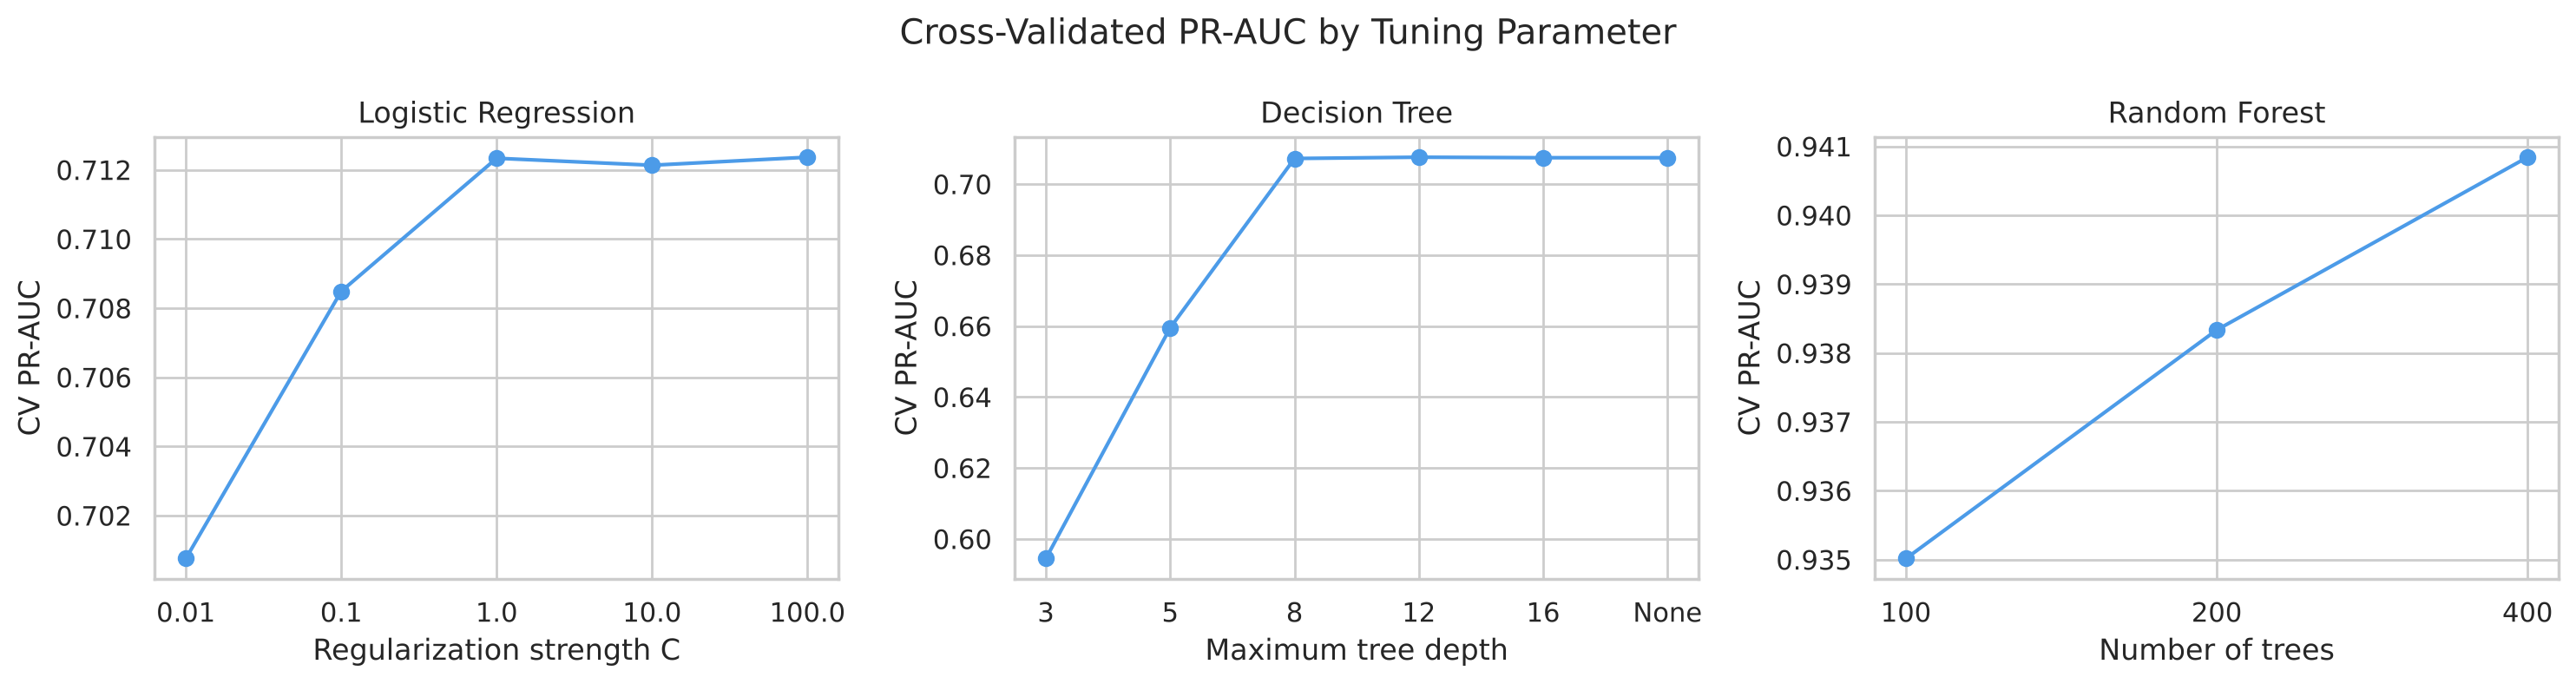

In [6]:
TUNING_PANELS = [
    ("Logistic Regression", "model__C", "Regularization strength C"),
    ("Decision Tree", "model__max_depth", "Maximum tree depth"),
    ("Random Forest", "model__n_estimators", "Number of trees"),
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, param, label) in zip(axes, TUNING_PANELS):
    results = pd.DataFrame(searches[name].cv_results_)
    values = results["param_" + param].map(
        lambda v: "None" if v is None else str(v)
    )
    best_scores = results.groupby(values, sort=False)["mean_test_score"].max()
    ax.plot(best_scores.index, best_scores.values, marker="o", color=BLUE)
    ax.set_title(name)
    ax.set_xlabel(label)
    ax.set_ylabel("CV PR-AUC")
fig.suptitle("Cross-Validated PR-AUC by Tuning Parameter")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "tuning_curves.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Model comparison on the test set

The tuned models are scored once on the held-out test set, next to a
baseline that always predicts the majority class. Precision, recall, and F1
are for the churn class at the default 0.5 threshold.

In [7]:
def evaluate(model, features, labels):
    """Return test metrics for a fitted classifier."""
    probabilities = model.predict_proba(features)[:, 1]
    predictions = (probabilities >= 0.5).astype(int)
    return {
        "Accuracy": accuracy_score(labels, predictions),
        "Precision": precision_score(labels, predictions, zero_division=0),
        "Recall": recall_score(labels, predictions),
        "F1": f1_score(labels, predictions),
        "ROC-AUC": roc_auc_score(labels, probabilities),
        "PR-AUC": average_precision_score(labels, probabilities),
    }


baseline = build_pipeline(DummyClassifier(strategy="most_frequent"))
baseline.fit(X_train, y_train)

fitted_models = {"Baseline (majority class)": baseline}
fitted_models.update(
    {name: search.best_estimator_ for name, search in searches.items()}
)

comparison = pd.DataFrame(
    {name: evaluate(m, X_test, y_test) for name, m in fitted_models.items()}
).T
comparison.insert(
    0,
    "CV PR-AUC",
    [np.nan] + [searches[name].best_score_ for name in searches],
)
comparison.to_csv(RESULTS_DIR / "model_comparison.csv", index_label="Model")
comparison.round(3)

,CV PR-AUC,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Baseline (majority class),NaN,0.834,0.000,0.000,0.000,0.500,0.166
Logistic Regression,0.712,0.882,0.707,0.488,0.577,0.875,0.685
Decision Tree,0.708,0.847,0.524,0.851,0.649,0.921,0.732
Random Forest,0.941,0.971,0.911,0.917,0.914,0.990,0.969


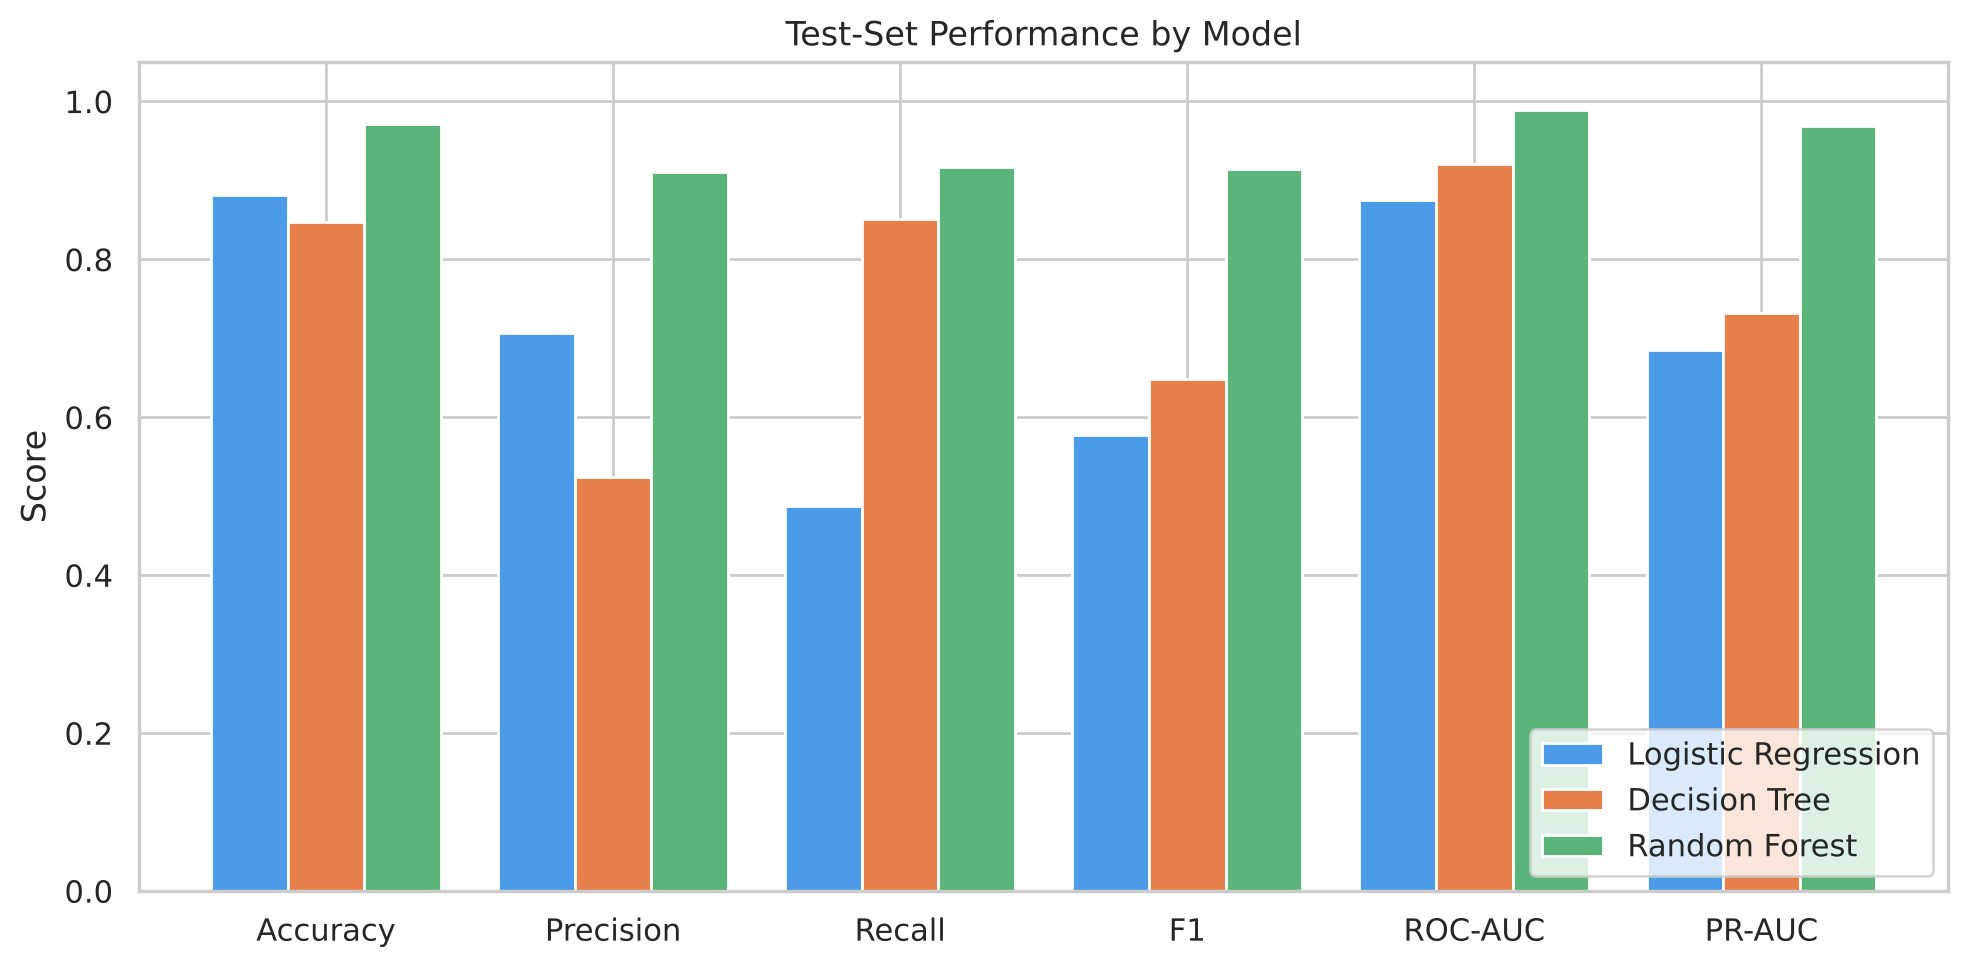

In [8]:
plot_data = comparison.drop(columns="CV PR-AUC").drop(
    index="Baseline (majority class)"
)
ax = plot_data.T.plot(
    kind="bar", figsize=(10, 5), width=0.8,
    color=[BLUE, ORANGE, "#5BB57A"],
)
ax.set_title("Test-Set Performance by Model")
ax.set_ylabel("Score")
ax.set_ylim(0, 1.05)
ax.tick_params(axis="x", rotation=0)
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(
    FIGURE_DIR / "model_comparison.png", dpi=150, bbox_inches="tight"
)
plt.show()

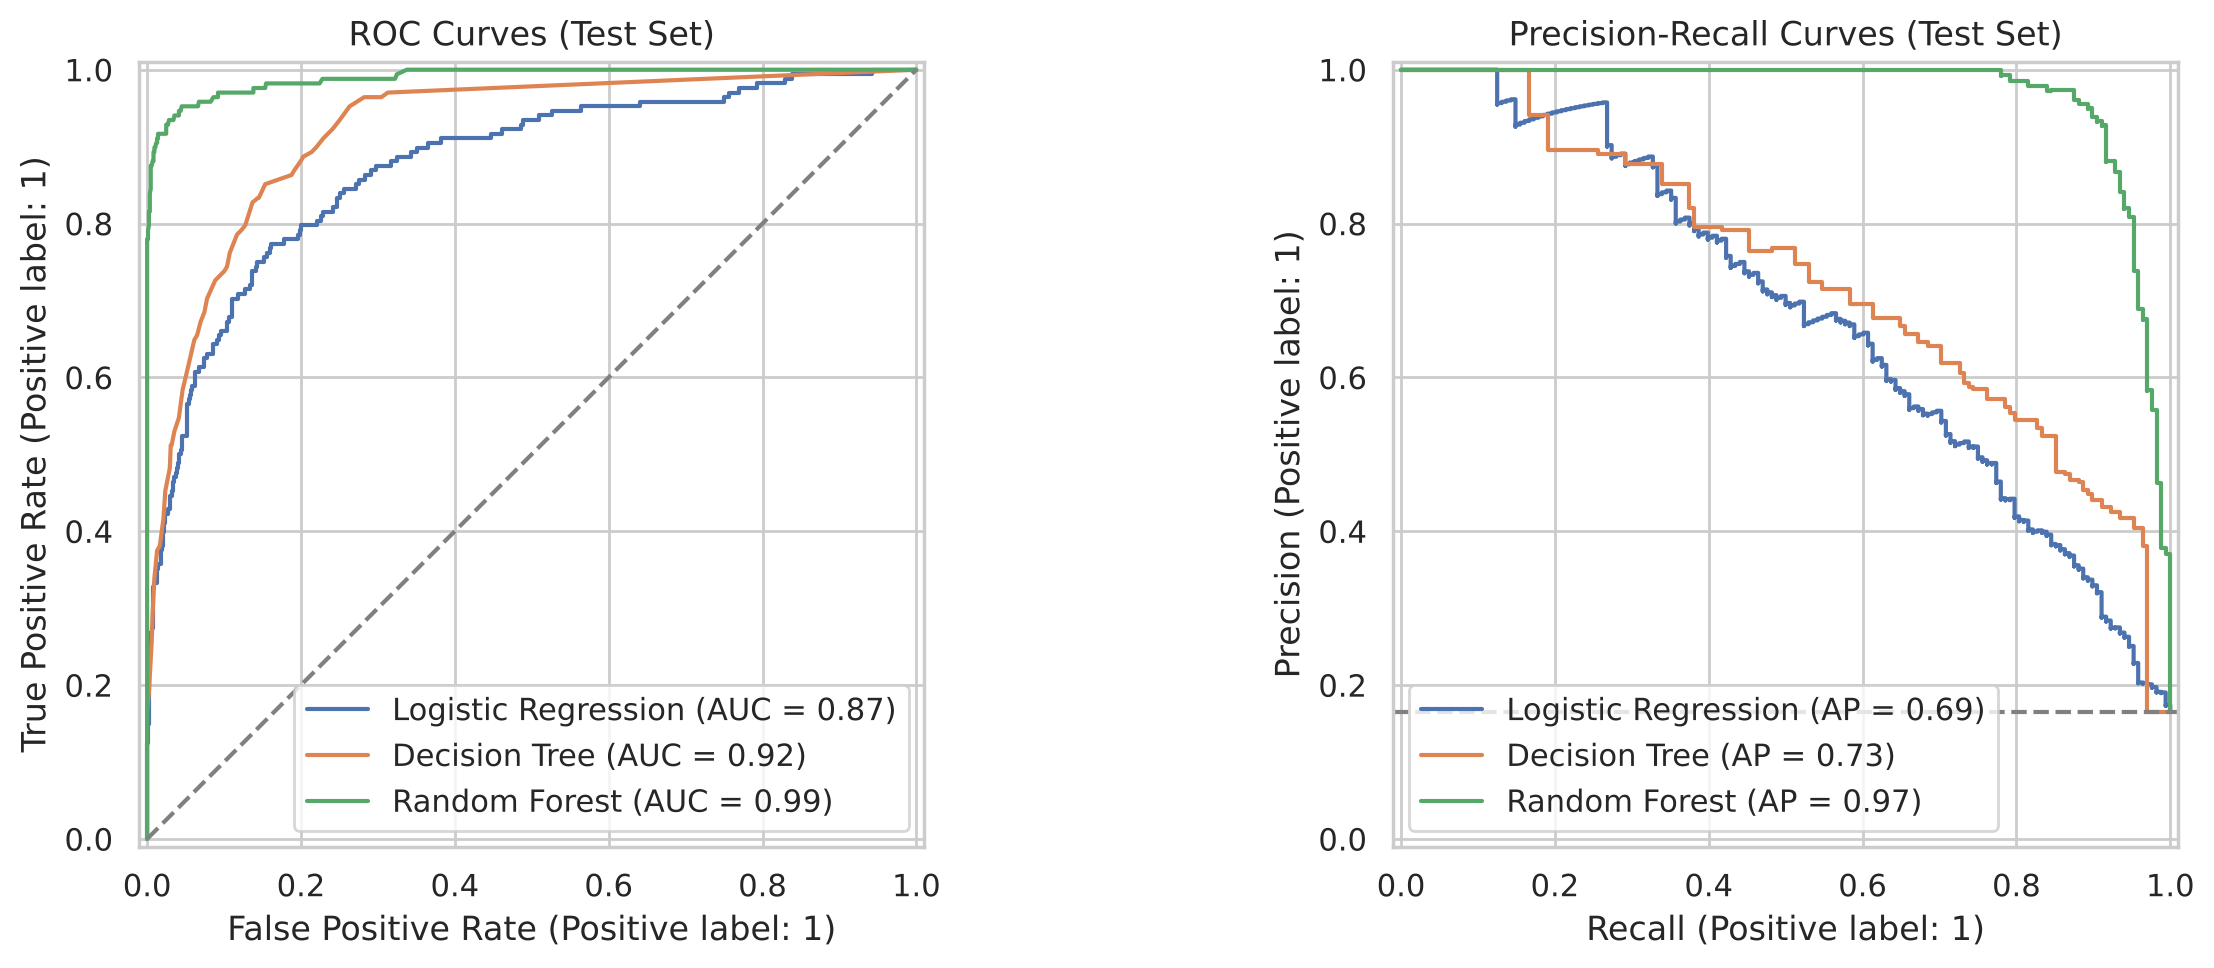

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name in searches:
    RocCurveDisplay.from_estimator(
        fitted_models[name], X_test, y_test, name=name, ax=axes[0]
    )
    PrecisionRecallDisplay.from_estimator(
        fitted_models[name], X_test, y_test, name=name, ax=axes[1]
    )
axes[0].plot([0, 1], [0, 1], linestyle="--", color="gray")
axes[0].set_title("ROC Curves (Test Set)")
axes[1].axhline(y_test.mean(), linestyle="--", color="gray")
axes[1].set_title("Precision-Recall Curves (Test Set)")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "roc_pr_curves.png", dpi=150, bbox_inches="tight")
plt.show()

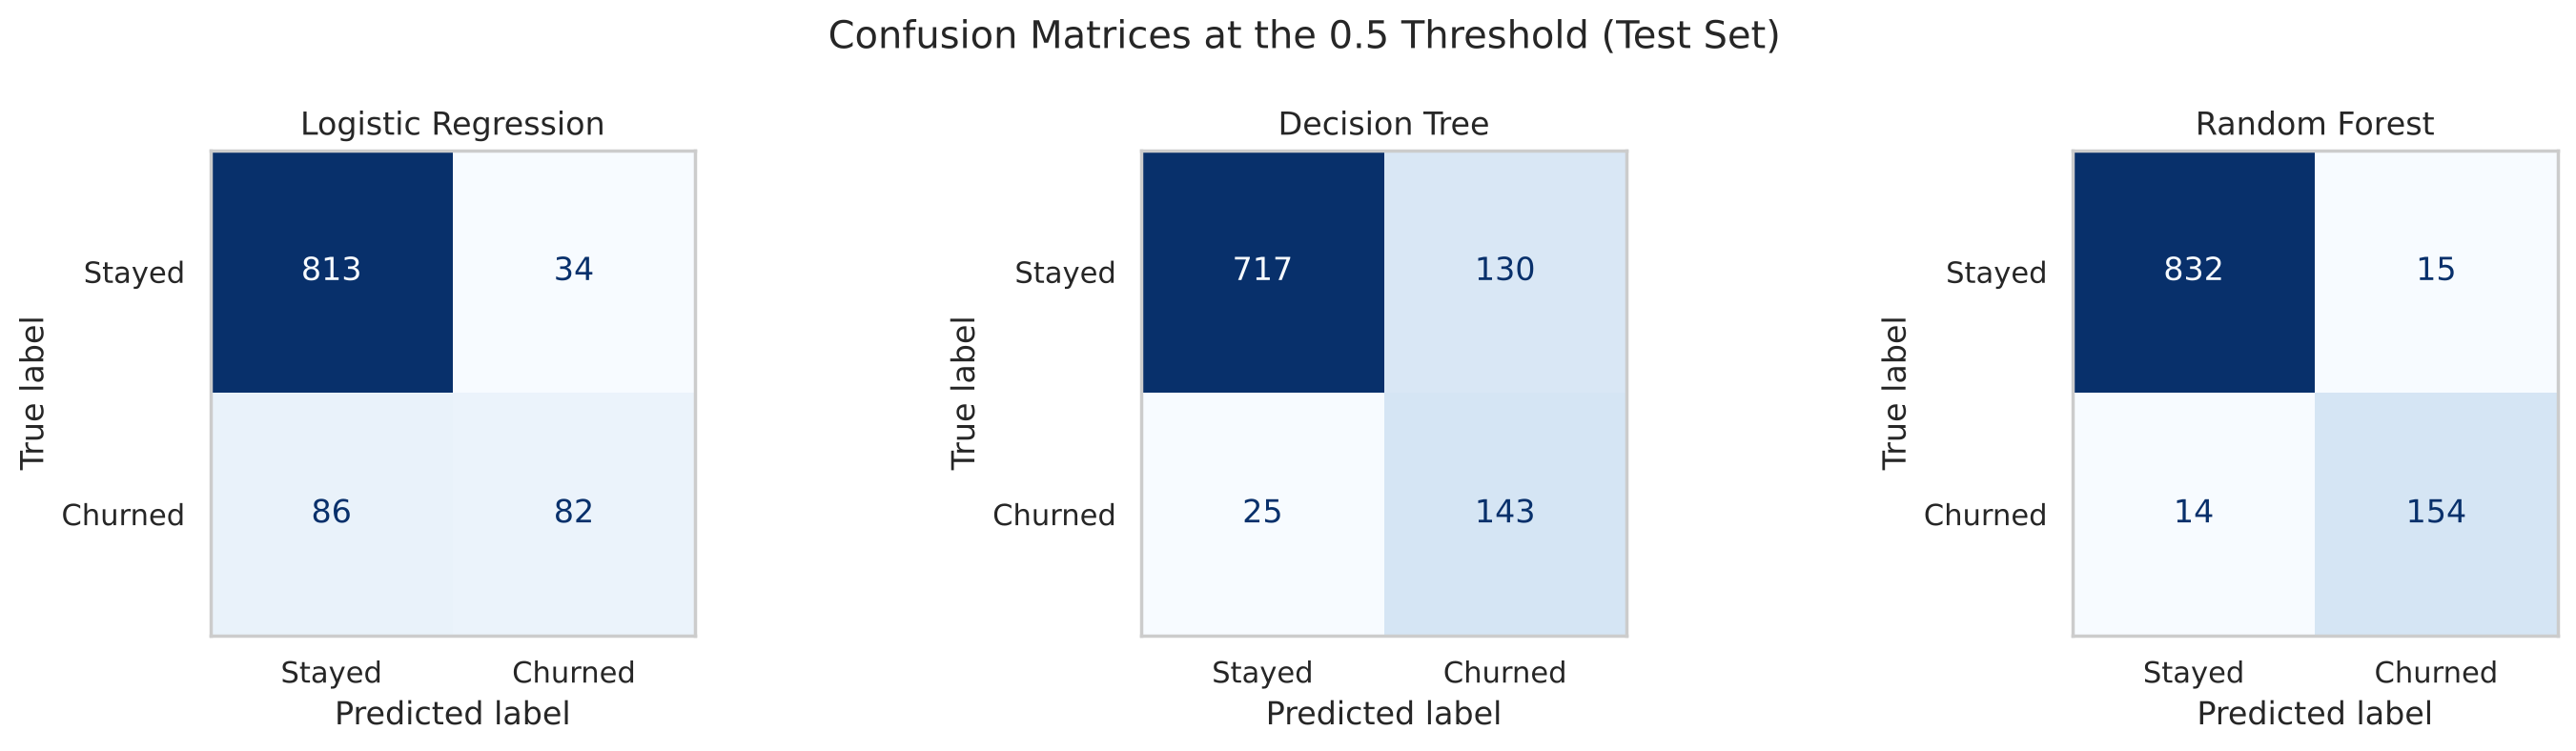

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, name in zip(axes, searches):
    ConfusionMatrixDisplay.from_estimator(
        fitted_models[name], X_test, y_test,
        display_labels=["Stayed", "Churned"], cmap="Blues",
        colorbar=False, ax=ax,
    )
    ax.set_title(name)
    ax.grid(False)
fig.suptitle("Confusion Matrices at the 0.5 Threshold (Test Set)")
fig.tight_layout()
fig.savefig(
    FIGURE_DIR / "confusion_matrices.png", dpi=150, bbox_inches="tight"
)
plt.show()

## 6. Which features drive churn?

Feature importance is measured with **permutation importance**: shuffle one
feature at a time and record how much the model's PR-AUC drops. It is
computed on a validation slice of the training data, so the test set stays
untouched and the ranking can be used for feature selection in section 7.
Unlike the random forest's built-in importances, it works on the original
columns (before one-hot encoding) and is not biased toward features with
many distinct values.

Best model by cross-validated PR-AUC: Random Forest


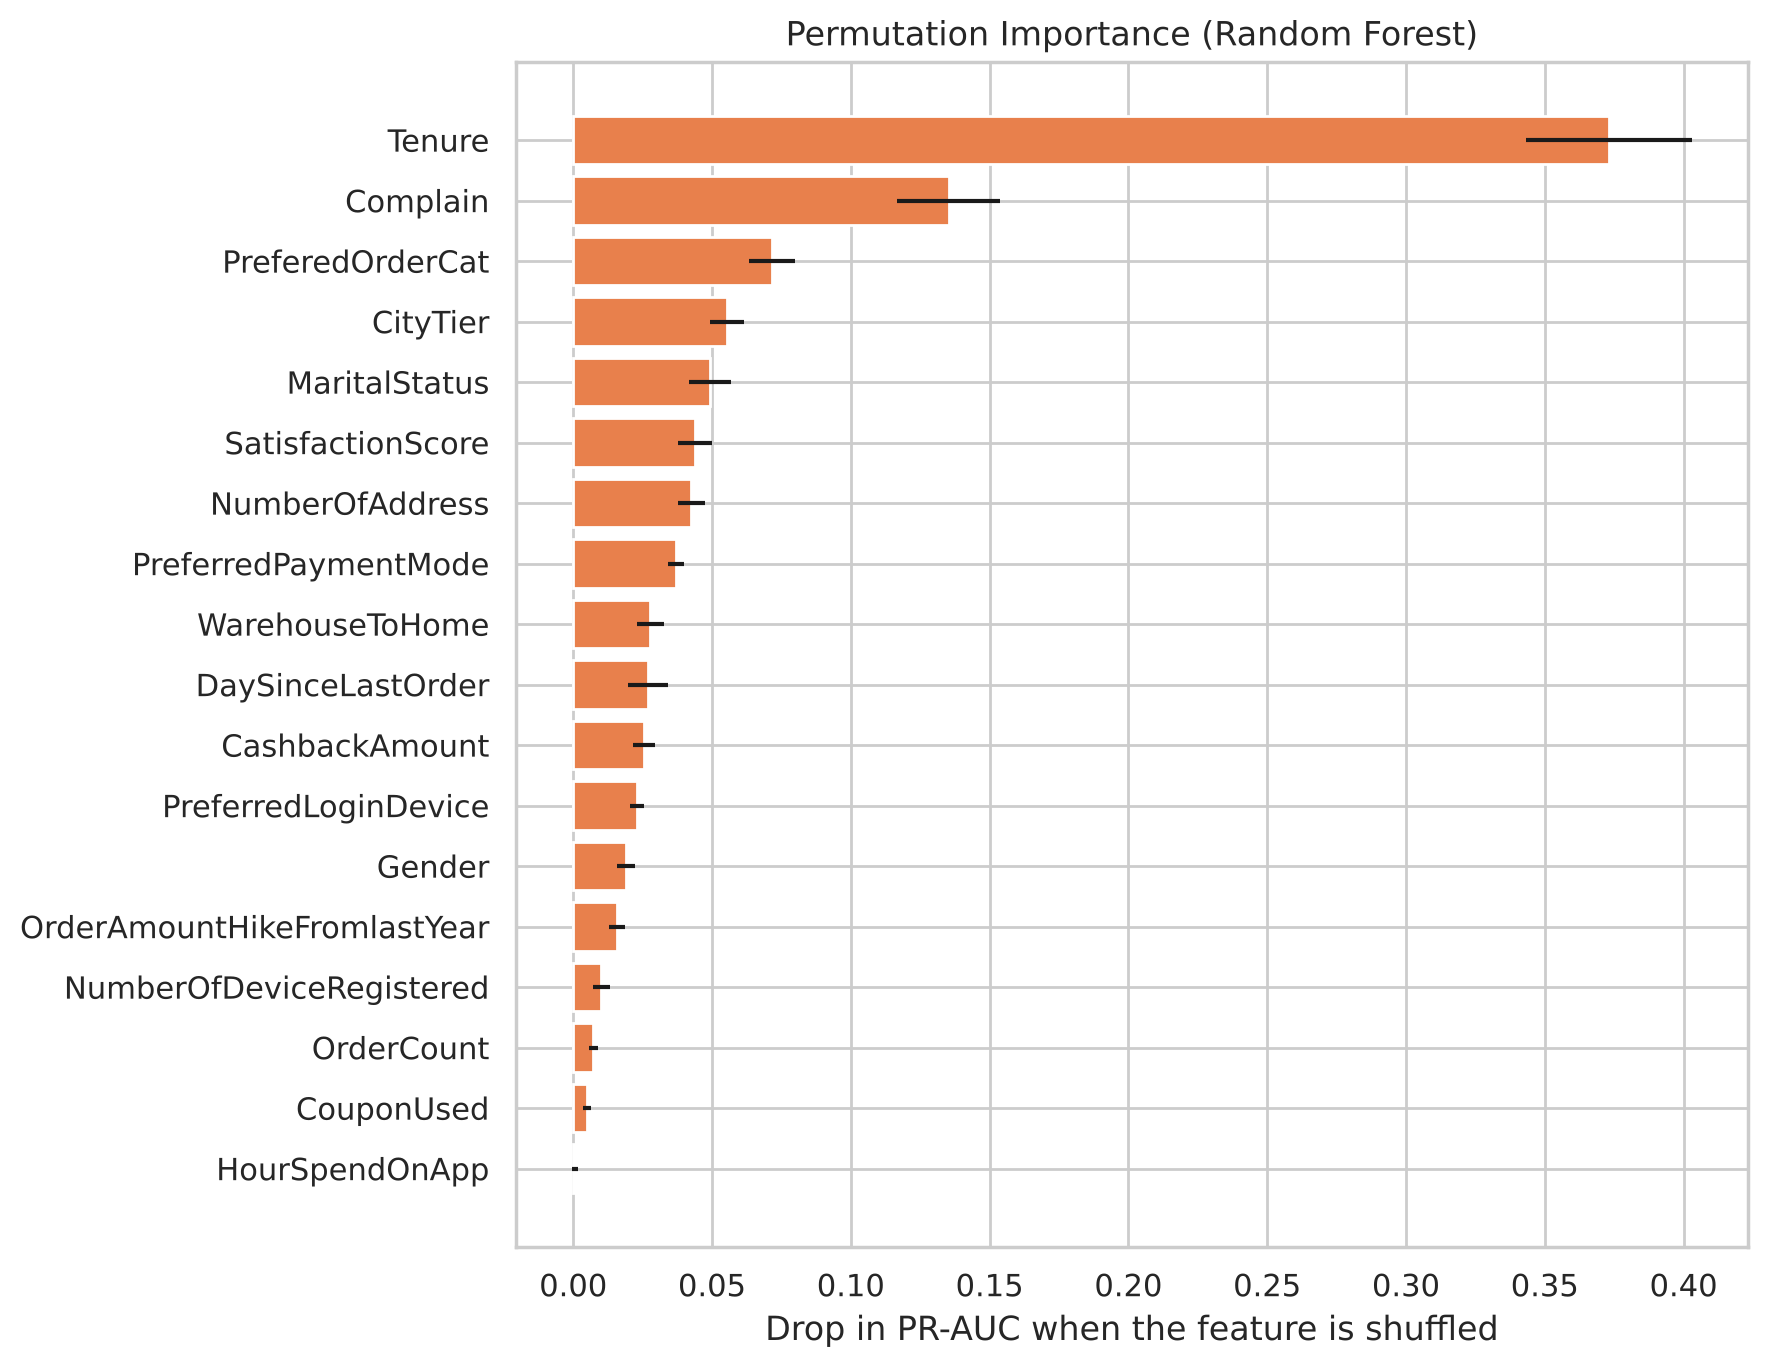

,Feature,Importance,Std
0,Tenure,0.3731,0.0299
1,Complain,0.1353,0.0185
2,PreferedOrderCat,0.0717,0.0083
3,CityTier,0.0554,0.0063
4,MaritalStatus,0.0494,0.0076
5,SatisfactionScore,0.0439,0.0062
6,NumberOfAddress,0.0426,0.0047
7,PreferredPaymentMode,0.0369,0.0029
8,WarehouseToHome,0.0278,0.0049
9,DaySinceLastOrder,0.0269,0.0073


In [11]:
best_name = comparison["CV PR-AUC"].idxmax()
best_params = {
    k.replace("model__", ""): v
    for k, v in searches[best_name].best_params_.items()
}
print("Best model by cross-validated PR-AUC:", best_name)


def make_best_model():
    """Return an unfitted copy of the best model with its tuned settings."""
    model = MODEL_SPECS[best_name][0]
    return model.__class__(**{**model.get_params(), **best_params})


X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train, test_size=0.25, stratify=y_train,
    random_state=RANDOM_STATE,
)
importance_model = build_pipeline(make_best_model()).fit(X_fit, y_fit)
permutation = permutation_importance(
    importance_model, X_val, y_val, scoring="average_precision",
    n_repeats=20, random_state=RANDOM_STATE, n_jobs=-1,
)
importance = pd.DataFrame({
    "Feature": ALL_FEATURES,
    "Importance": permutation.importances_mean,
    "Std": permutation.importances_std,
}).sort_values("Importance", ascending=False).reset_index(drop=True)
importance.to_csv(RESULTS_DIR / "feature_importance.csv", index=False)

ordered = importance.iloc[::-1]
plt.figure(figsize=(9, 7))
plt.barh(
    ordered["Feature"], ordered["Importance"], xerr=ordered["Std"],
    color=ORANGE,
)
plt.title(f"Permutation Importance ({best_name})")
plt.xlabel("Drop in PR-AUC when the feature is shuffled")
plt.tight_layout()
plt.savefig(
    FIGURE_DIR / "feature_importance.png", dpi=150, bbox_inches="tight"
)
plt.show()

importance.round(4)

### Direction of the effects

Permutation importance shows how much a feature matters, not which way it
pushes. The logistic regression coefficients give the direction: positive
values raise the odds of churn, negative values lower them (numeric features
are standardized, so each coefficient is the effect of a one standard
deviation increase).

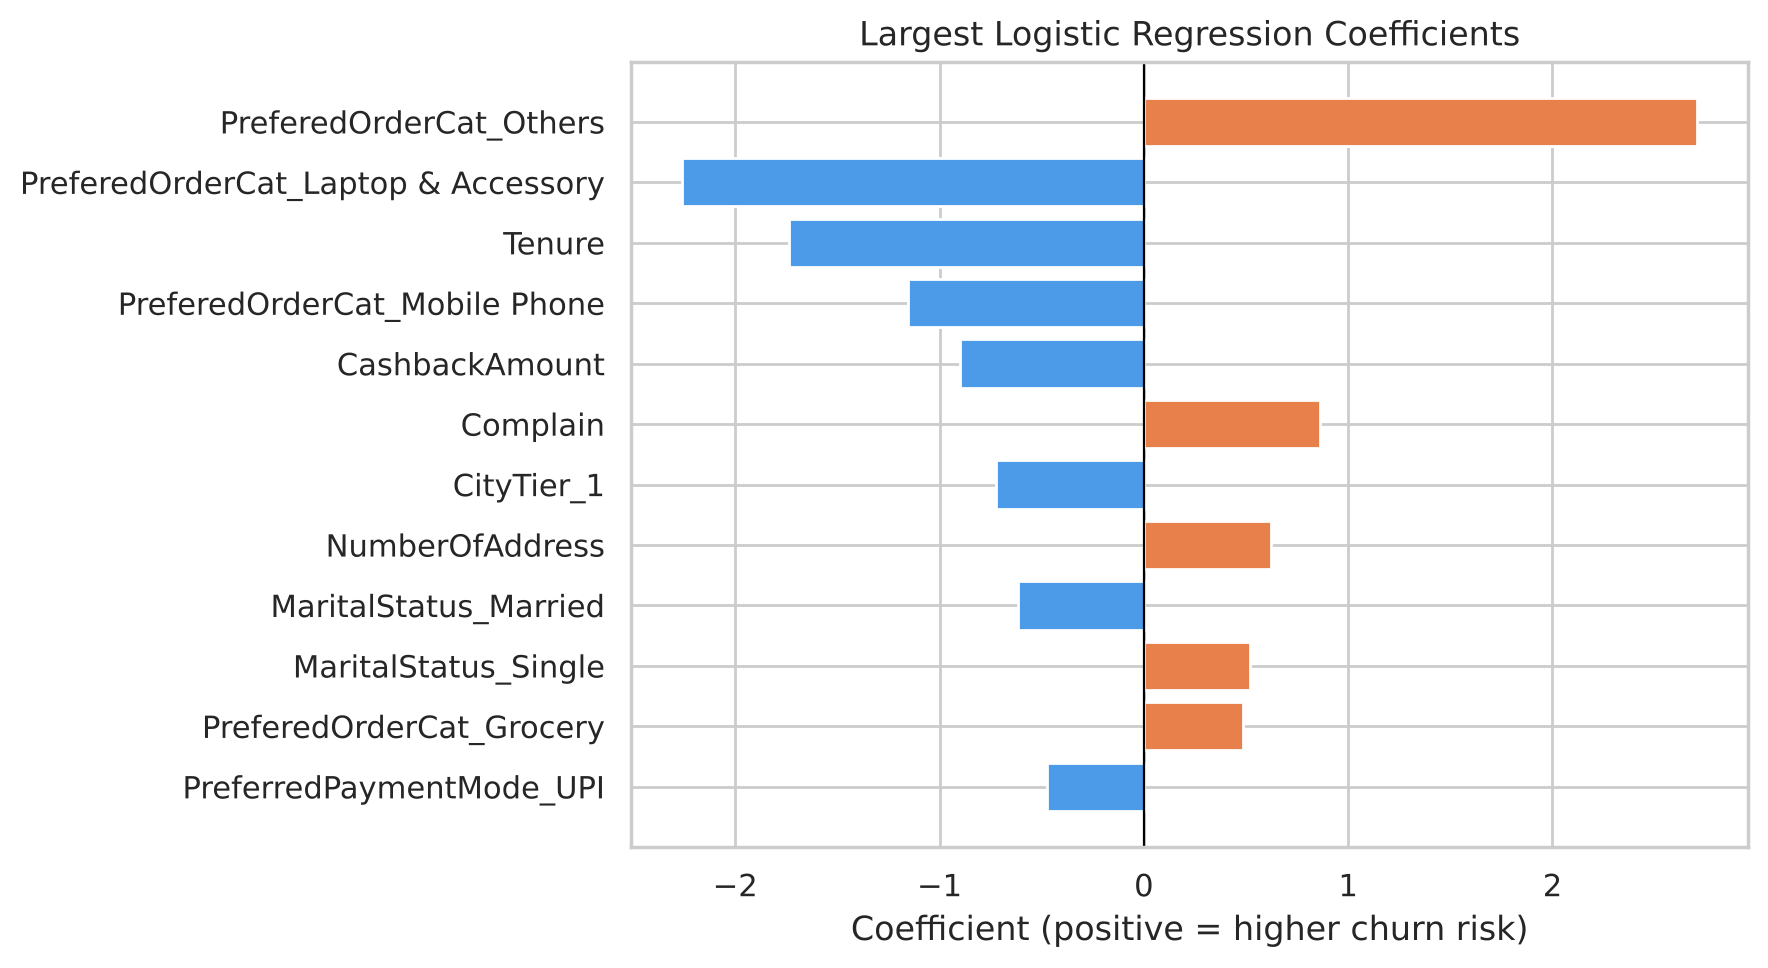

In [12]:
logistic = fitted_models["Logistic Regression"]
coefficients = pd.Series(
    logistic.named_steps["model"].coef_[0],
    index=logistic.named_steps["prep"].get_feature_names_out(),
)
coefficients.index = coefficients.index.str.replace(
    r"^(num|cat)__", "", regex=True
)
strongest = coefficients.reindex(
    coefficients.abs().sort_values(ascending=False).index
).head(12)

plt.figure(figsize=(9, 5))
colors = [ORANGE if value > 0 else BLUE for value in strongest.iloc[::-1]]
plt.barh(strongest.index[::-1], strongest.iloc[::-1], color=colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Largest Logistic Regression Coefficients")
plt.xlabel("Coefficient (positive = higher churn risk)")
plt.tight_layout()
plt.savefig(
    FIGURE_DIR / "logistic_coefficients.png", dpi=150, bbox_inches="tight"
)
plt.show()

## 7. A simpler model with only the strongest features

Features are added in order of importance, and the best model is re-scored
with 5-fold cross-validation at each step. The reduced model uses the
smallest feature set whose PR-AUC is within 0.02 of the full model.

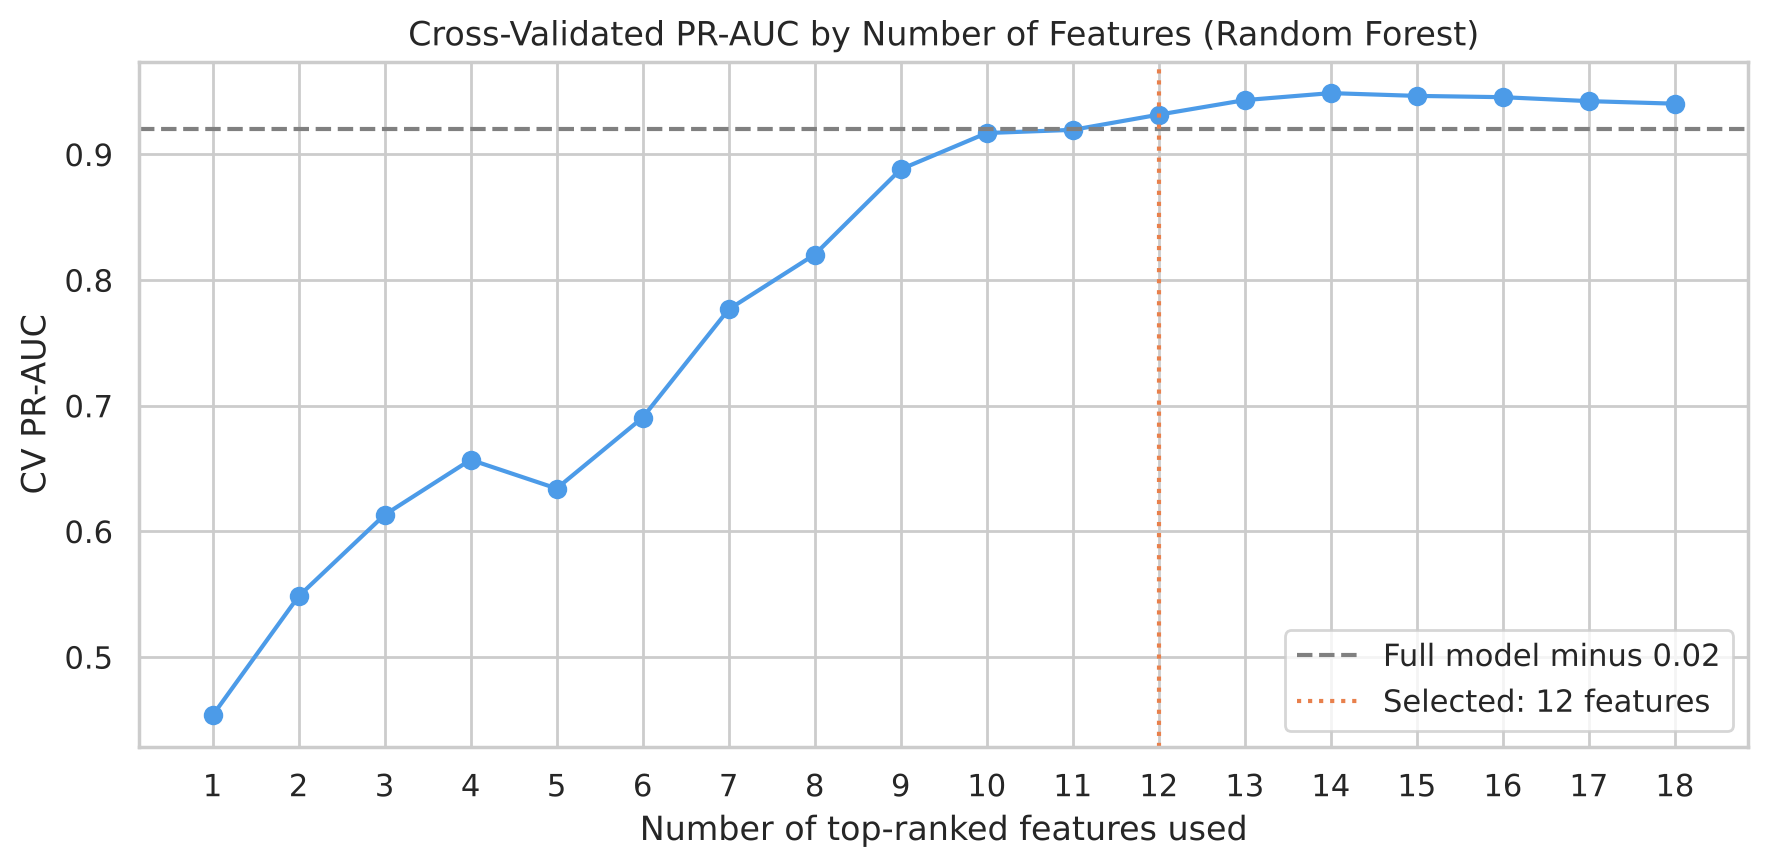

Reduced model: 12 of 18 features
['Tenure', 'Complain', 'PreferedOrderCat', 'CityTier', 'MaritalStatus', 'SatisfactionScore', 'NumberOfAddress', 'PreferredPaymentMode', 'WarehouseToHome', 'DaySinceLastOrder', 'CashbackAmount', 'PreferredLoginDevice']


In [13]:
TOLERANCE = 0.02
ranked_features = importance["Feature"].tolist()

count_scores = {}
for count in range(1, len(ranked_features) + 1):
    pipeline = build_pipeline(make_best_model(), ranked_features[:count])
    scores = cross_val_score(
        pipeline, X_train, y_train, scoring="average_precision", cv=cv,
        n_jobs=-1,
    )
    count_scores[count] = scores.mean()
count_scores = pd.Series(count_scores)

full_score = count_scores.iloc[-1]
good_enough = count_scores[count_scores >= full_score - TOLERANCE]
reduced_count = int(good_enough.index[0])
reduced_features = ranked_features[:reduced_count]

plt.figure(figsize=(9, 4.5))
plt.plot(count_scores.index, count_scores.values, marker="o", color=BLUE)
plt.axhline(
    full_score - TOLERANCE, linestyle="--", color="gray",
    label=f"Full model minus {TOLERANCE}",
)
plt.axvline(
    reduced_count, linestyle=":", color=ORANGE,
    label=f"Selected: {reduced_count} features",
)
plt.title(f"Cross-Validated PR-AUC by Number of Features ({best_name})")
plt.xlabel("Number of top-ranked features used")
plt.ylabel("CV PR-AUC")
plt.xticks(count_scores.index)
plt.legend()
plt.tight_layout()
plt.savefig(FIGURE_DIR / "feature_count.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Reduced model: {reduced_count} of {len(ranked_features)} features")
print(reduced_features)

In [14]:
reduced_model = build_pipeline(make_best_model(), reduced_features)
reduced_model.fit(X_train, y_train)

full_label = f"{best_name} (all {len(ALL_FEATURES)} features)"
reduced_label = f"{best_name} (top {reduced_count} features)"
reduced_comparison = pd.DataFrame({
    full_label: evaluate(fitted_models[best_name], X_test, y_test),
    reduced_label: evaluate(reduced_model, X_test, y_test),
}).T
reduced_comparison.to_csv(
    RESULTS_DIR / "reduced_model_comparison.csv", index_label="Model"
)
reduced_comparison.round(3)

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Random Forest (all 18 features),0.971,0.911,0.917,0.914,0.990,0.969
Random Forest (top 12 features),0.970,0.906,0.917,0.911,0.992,0.969


## 8. Export churn probabilities

One churn probability per customer from the best full model, for the
clustering and decision-threshold analysis. Test-set customers are scored by
the final model. Training-set customers get **out-of-fold** probabilities
(each scored by a model that did not see them), so their scores are not
inflated by the model having memorized them. The `Split` column records the
train/test assignment used throughout this notebook.

In [15]:
best_pipeline = fitted_models[best_name]
out_of_fold = cross_val_predict(
    build_pipeline(make_best_model()), X_train, y_train, cv=cv,
    method="predict_proba", n_jobs=-1,
)[:, 1]

predictions = pd.DataFrame({
    ID_COLUMN: df[ID_COLUMN],
    "Split": "train",
    TARGET: y,
    "ChurnProbability": np.nan,
})
predictions.loc[X_test.index, "Split"] = "test"
predictions.loc[X_train.index, "ChurnProbability"] = out_of_fold
predictions.loc[X_test.index, "ChurnProbability"] = (
    best_pipeline.predict_proba(X_test)[:, 1]
)
predictions["ChurnProbability"] = predictions["ChurnProbability"].round(4)
predictions.to_csv(DATA_DIR / "churn_predictions.csv", index=False)

print("Saved churn_predictions.csv:", predictions.shape)
print(predictions.groupby("Split")["ChurnProbability"].describe().round(3))
predictions.head()

Saved churn_predictions.csv: (5073, 4)
        count   mean    std  min    25%    50%    75%    max
Split                                                       
test   1015.0  0.224  0.286  0.0  0.040  0.090  0.274  0.995
train  4058.0  0.225  0.275  0.0  0.045  0.098  0.272  0.998


,CustomerID,Split,Churn,ChurnProbability
0,50001,train,1,0.8775
1,50002,train,1,0.7625
2,50003,train,1,0.7550
3,50004,train,1,0.6325
4,50005,train,1,0.4675


## 9. Caveat: near-duplicate customers

The random forest scores far above the other two models, which is worth
questioning. Even after exact duplicates were removed in notebook 01, many
customers in this dataset differ from another customer in only one or two
fields. When one of a pair lands in the training set and the other in the
test set, a flexible model can recognize the test customer almost directly.

The check below finds, for each test customer, the most similar training
customer and splits the test set into customers with a near-twin (at most
two differing features) and customers without one.

In [16]:
def closest_match_counts(queries, references):
    """Count matching features between each query row and its closest
    reference row."""
    return np.array(
        [(references == row).sum(axis=1).max() for row in queries]
    )


closest = closest_match_counts(
    X_test.astype(str).to_numpy(), X_train.astype(str).to_numpy()
)
has_twin = closest >= len(ALL_FEATURES) - 2

twin_rows = []
for label, mask in (("Near-twin in training set", has_twin),
                    ("No near-twin", ~has_twin)):
    for name in searches:
        metrics = evaluate(fitted_models[name], X_test[mask], y_test[mask])
        twin_rows.append({
            "Test customers": label,
            "Count": int(mask.sum()),
            "Model": name,
            "Recall": metrics["Recall"],
            "F1": metrics["F1"],
            "PR-AUC": metrics["PR-AUC"],
        })
twin_comparison = pd.DataFrame(twin_rows)
twin_comparison.to_csv(
    RESULTS_DIR / "near_duplicate_check.csv", index=False
)

print("Test customers with a near-twin: {:.0f}%".format(has_twin.mean() * 100))
twin_comparison.round(3)

Test customers with a near-twin: 52%


,Test customers,Count,Model,Recall,F1,PR-AUC
0,Near-twin in training set,530,Logistic Regression,0.480,0.576,0.709
1,Near-twin in training set,530,Decision Tree,0.853,0.685,0.790
2,Near-twin in training set,530,Random Forest,1.000,0.986,1.000
3,No near-twin,485,Logistic Regression,0.500,0.579,0.657
4,No near-twin,485,Decision Tree,0.848,0.599,0.663
5,No near-twin,485,Random Forest,0.788,0.800,0.881
